<a href="https://colab.research.google.com/github/Usman-938/CNN/blob/main/mnist_cnn_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# Assignment 1: MNIST Digit Classification using CNN (PyTorch)
# Steps: 1) Load 7,000 samples  2) Split dataset (80/20)
#        3) Train CNN model     4) Check performance
# Platform: Google Colab
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

In [2]:
# ------------------------------------------------------------
# Settings (you can change these values)
# ------------------------------------------------------------
NUM_SAMPLES = 7000      # total images to use (as given in assignment)
TEST_RATIO = 0.20       # 20 percent data for testing
BATCH_SIZE = 64         # number of images processed at once
EPOCHS = 5              # number of times the model sees full training data
LEARNING_RATE = 0.001   # step size for the optimizer
SEED = 42               # fixed seed so results are repeatable

# Fix random seeds so every run gives similar results
torch.manual_seed(SEED)
np.random.seed(SEED)

# Use GPU if available in Colab, otherwise use CPU
# (In Colab: Runtime > Change runtime type > T4 GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [3]:

# STEP 1: INPUT - Load the MNIST dataset (7,000 samples)
# Convert images to tensors and normalize pixel values
transform = transforms.Compose([
    transforms.ToTensor(),                      # image -> tensor (0 to 1)
    transforms.Normalize((0.1307,), (0.3081,))  # standard MNIST mean and std
])

# Download the full MNIST training set (60,000 images)
full_dataset = datasets.MNIST(root="./data", train=True,
                              download=True, transform=transform)

# Pick 7,000 random images from the full dataset
indices = np.random.permutation(len(full_dataset))[:NUM_SAMPLES]
dataset = Subset(full_dataset, indices)
print("Total samples loaded:", len(dataset))

100%|██████████| 9.91M/9.91M [00:11<00:00, 878kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 130kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]

Total samples loaded: 7000


In [4]:

# STEP 2: SPLITTING DATASET - 80 percent train, 20 percent test
test_size = int(NUM_SAMPLES * TEST_RATIO)   # 1400 images
train_size = NUM_SAMPLES - test_size        # 5600 images

train_dataset, test_dataset = random_split(
    dataset, [train_size, test_size],
    generator=torch.Generator().manual_seed(SEED)
)
print("Training samples:", len(train_dataset))
print("Testing samples :", len(test_dataset))

# DataLoader gives data to the model in small batches
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Training samples: 5600
Testing samples : 1400


In [5]:

# STEP 3: MODEL TRAINING - Define and train the CNN
class SimpleCNN(nn.Module):
    """A simple CNN with 2 convolution layers and 2 fully connected layers."""

    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Convolution block 1: 1 input channel -> 16 feature maps
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        # Convolution block 2: 16 feature maps -> 32 feature maps
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        # Pooling layer reduces the image size by half
        self.pool = nn.MaxPool2d(2, 2)
        # Activation function
        self.relu = nn.ReLU()
        # Fully connected layers (image is 28x28 -> 14x14 -> 7x7 after pooling)
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)   # 10 outputs for digits 0 to 9

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))   # conv1 -> relu -> pool
        x = self.pool(self.relu(self.conv2(x)))   # conv2 -> relu -> pool
        x = x.view(x.size(0), -1)                 # flatten to a vector
        x = self.relu(self.fc1(x))                # fully connected layer
        x = self.fc2(x)                           # final scores for 10 classes
        return x


model = SimpleCNN().to(device)

# Loss function: measures how wrong the predictions are
criterion = nn.CrossEntropyLoss()
# Optimizer: updates the model weights to reduce the loss
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Lists to store loss and accuracy for plotting later
train_losses = []
train_accuracies = []

print("\nTraining started...")
for epoch in range(EPOCHS):
    model.train()               # set model to training mode
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()               # clear old gradients
        outputs = model(images)             # forward pass
        loss = criterion(outputs, labels)   # calculate loss
        loss.backward()                     # backward pass (find gradients)
        optimizer.step()                    # update weights

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)    # class with highest score
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)
    print(f"Epoch {epoch + 1}/{EPOCHS} - Loss: {epoch_loss:.4f} - Accuracy: {epoch_acc:.2f}%")

print("Training finished.")


Training started...
Epoch 1/5 - Loss: 0.7914 - Accuracy: 75.86%
Epoch 2/5 - Loss: 0.2242 - Accuracy: 93.20%
Epoch 3/5 - Loss: 0.1353 - Accuracy: 95.95%
Epoch 4/5 - Loss: 0.0963 - Accuracy: 97.18%
Epoch 5/5 - Loss: 0.0759 - Accuracy: 97.70%
Training finished.



Test Accuracy: 96.79%

Classification Report:
              precision    recall  f1-score   support

           0     0.9695    0.9695    0.9695       131
           1     0.9939    0.9939    0.9939       165
           2     0.9730    0.9412    0.9568       153
           3     0.9618    0.9767    0.9692       129
           4     0.9640    0.9371    0.9504       143
           5     0.9695    0.9695    0.9695       131
           6     1.0000    0.9924    0.9962       132
           7     0.9375    0.9854    0.9609       137
           8     0.9407    0.9621    0.9513       132
           9     0.9655    0.9524    0.9589       147

    accuracy                         0.9679      1400
   macro avg     0.9675    0.9680    0.9677      1400
weighted avg     0.9681    0.9679    0.9679      1400



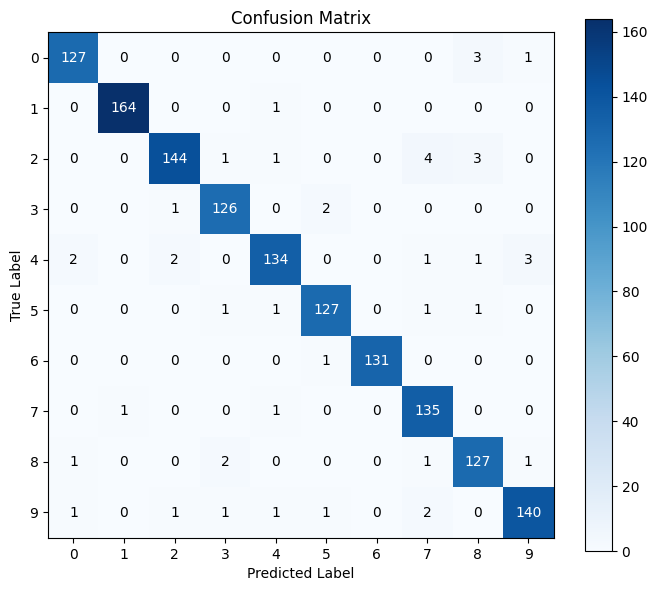

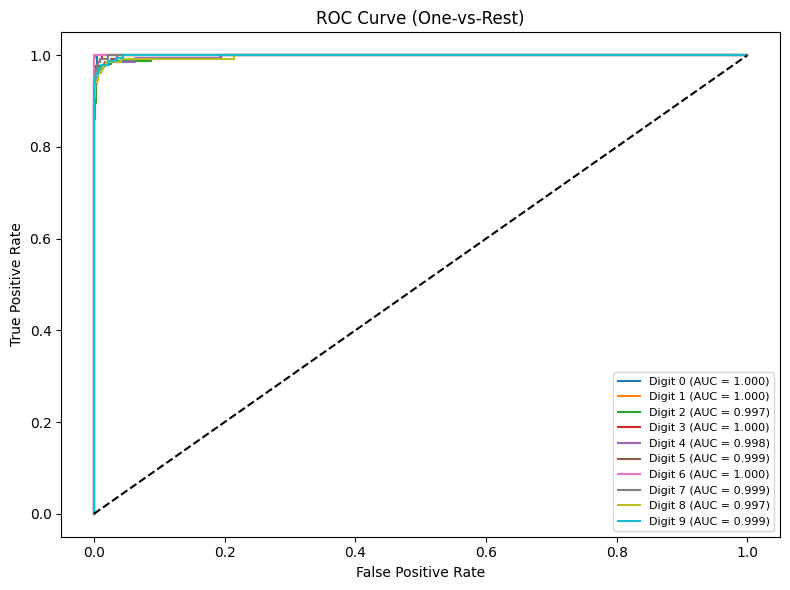

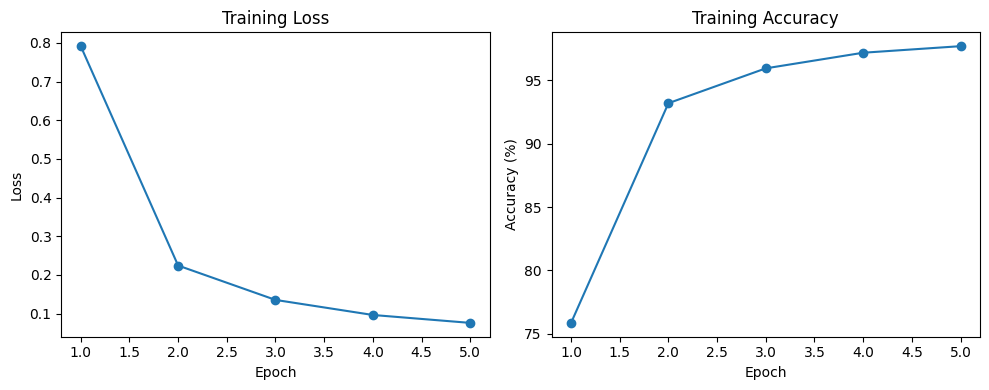

Model saved as mnist_cnn.pth


In [6]:

# STEP 4: PERFORMANCE - Test the model on unseen 20 percent data
model.eval()                    # set model to evaluation mode
all_labels = []                 # true labels
all_preds = []                  # predicted labels
all_probs = []                  # predicted probabilities (needed for ROC)

with torch.no_grad():           # no gradient calculation during testing
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)   # convert scores to probabilities
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predicted.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_labels = np.array(all_labels)
all_preds = np.array(all_preds)
all_probs = np.array(all_probs)

# 4a) Test accuracy
test_acc = 100.0 * np.mean(all_labels == all_preds)
print(f"\nTest Accuracy: {test_acc:.2f}%")

# 4b) Precision, recall and F1-score for every digit
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, digits=4))

# 4c) Confusion matrix (rows = actual digit, columns = predicted digit)
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.colorbar()
plt.xticks(range(10))
plt.yticks(range(10))
# Write the count inside each box
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# 4d) ROC curve (one-vs-rest, one curve for each digit)
# Convert labels to one-hot form for multi-class ROC
labels_bin = label_binarize(all_labels, classes=list(range(10)))

plt.figure(figsize=(8, 6))
for digit in range(10):
    fpr, tpr, _ = roc_curve(labels_bin[:, digit], all_probs[:, digit])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"Digit {digit} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--")     # diagonal line = random guessing
plt.title("ROC Curve (One-vs-Rest)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("roc_curve.png")
plt.show()

# 4e) Training loss and accuracy graph
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), train_accuracies, marker="o")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.tight_layout()
plt.savefig("training_curves.png")
plt.show()

# Save the trained model so it can be used later
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Model saved as mnist_cnn.pth")